In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 160
plt.rcParams["font.size"] = 10

ARTIFACTS = Path("artifacts")
FIG_DIR = ARTIFACTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS = {}


def purity_score(y_true, y_pred):
    table = pd.crosstab(np.asarray(y_pred), np.asarray(y_true))
    return table.max(axis=1).sum() / len(y_true)


def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, bbox_inches="tight")

## 1. Первичный анализ данных

In [2]:
dataset_path = Path("../1lab/perfume_type_classification_dataset.csv")
if not dataset_path.exists():
    dataset_path = Path("perfume_type_classification_dataset.csv")
df = pd.read_csv(dataset_path)
df.head()

,longevity_hours,sillage_score,top_note_count,price_usd,concentration_percent,fragrance_family,brand_tier,gender_target,contains_alcohol,limited_edition,perfume_category
0,5.96,5.80,5,103.71,17.04,Floral,Designer,Men,0.0,0,Eau de Parfum
1,8.85,7.70,4,122.93,15.28,Oriental,Luxury,Men,1.0,0,Eau de Toilette
2,0.54,2.67,3,105.21,12.69,Fresh,Designer,Men,0.0,0,Eau de Toilette
3,9.83,8.06,7,165.64,20.95,Floral,Luxury,Women,1.0,0,Eau de Parfum
4,11.03,9.72,5,279.00,25.00,Oriental,Luxury,Women,1.0,0,Perfume Extract


| Признак | Описание |
|---|---|
| longevity_hours | Стойкость аромата, часы |
| sillage_score | Интенсивность шлейфа (1–10) |
| top_note_count | Число верхних нот |
| price_usd | Розничная цена, доллары США |
| concentration_percent | Концентрация эфирных масел, % |
| fragrance_family | Floral / Woody / Oriental / Fresh / Citrus |
| brand_tier | Luxury / Designer / Niche / Drugstore |
| gender_target | Men / Women / Unisex |
| contains_alcohol | 0/1 — наличие спирта |
| limited_edition | 0/1 — лимитированная серия |
| perfume_category | Eau de Cologne / Eau de Toilette / Eau de Parfum / Perfume Extract |

Набор содержит 70 000 записей и 11 столбцов: 10 признаков и целевую переменную
`perfume_category` с четырьмя классами. Целевая переменная используется только для
оценки согласия кластеров с реальным разбиением и не участвует в обучении моделей.

In [3]:
df.describe()

,longevity_hours,sillage_score,top_note_count,price_usd,concentration_percent,contains_alcohol,limited_edition
count,70000.000000,70000.000000,70000.000000,69272.000000,70000.000000,68251.000000,70000.000000
mean,5.702075,5.572562,5.366800,98.586296,13.467856,0.853350,0.122386
std,3.180509,2.452350,2.408247,69.429082,7.500726,0.353759,0.327733
min,0.500000,1.000000,1.000000,10.000000,1.500000,0.000000,0.000000
25%,3.360000,3.770000,4.000000,42.740000,7.820000,1.000000,0.000000
50%,5.530000,5.580000,5.000000,89.700000,12.910000,1.000000,0.000000
75%,7.810000,7.390000,7.000000,141.902500,18.410000,1.000000,0.000000
max,16.000000,10.000000,10.000000,428.130000,35.000000,1.000000,1.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   longevity_hours        70000 non-null  float64
 1   sillage_score          70000 non-null  float64
 2   top_note_count         70000 non-null  int64  
 3   price_usd              69272 non-null  float64
 4   concentration_percent  70000 non-null  float64
 5   fragrance_family       70000 non-null  object 
 6   brand_tier             66497 non-null  object 
 7   gender_target          70000 non-null  object 
 8   contains_alcohol       68251 non-null  float64
 9   limited_edition        70000 non-null  int64  
 10  perfume_category       70000 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 5.9+ MB


### Очистка данных

In [5]:
n_rows_raw = int(len(df))
n_duplicates = int(df.duplicated().sum())
missing_raw = df.isna().sum()
n_duplicates

15000

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
missing_clean = df.isna().sum()
missing_clean

longevity_hours             0
sillage_score               0
top_note_count              0
price_usd                 550
concentration_percent       0
fragrance_family            0
brand_tier               2750
gender_target               0
contains_alcohol         1375
limited_edition             0
perfume_category            0
dtype: int64

In [7]:
X = df.drop(columns="perfume_category")
y = df["perfume_category"]
cat_cols = [column for column in X.columns if X[column].dtype == object]
num_cols = [column for column in X.columns if column not in cat_cols]

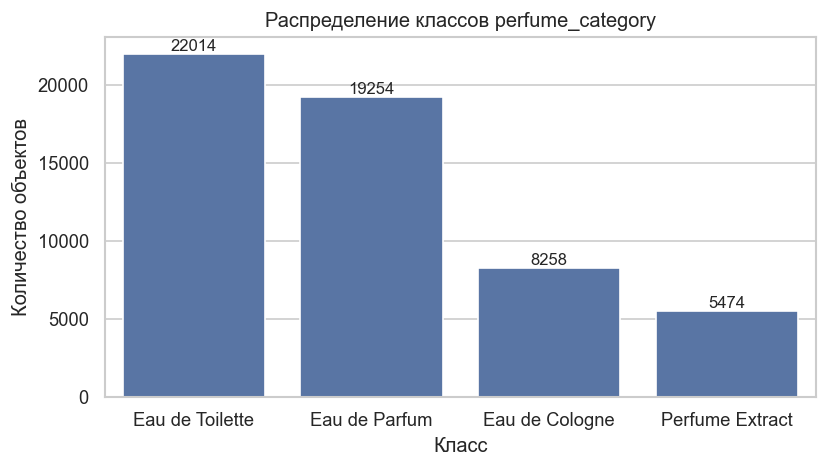

In [8]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=df,
    x="perfume_category",
    order=df["perfume_category"].value_counts().index,
)
ax.set_title("Распределение классов perfume_category")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество объектов")
for patch in ax.patches:
    ax.annotate(
        f"{int(patch.get_height())}",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center",
        va="bottom",
    )
save_figure("fig01_target.png")
plt.show()

### Визуализация значимых признаков

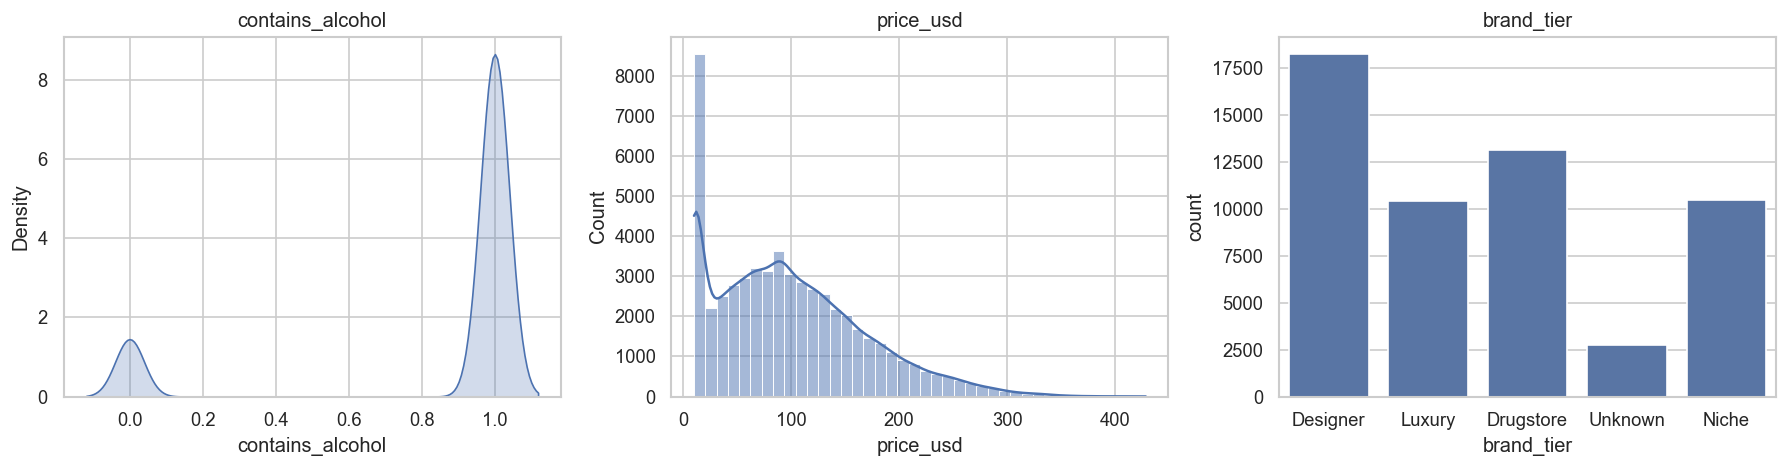

In [9]:
df_vis = df.copy()
df_vis[num_cols] = df_vis[num_cols].fillna(df_vis[num_cols].median())
df_vis[cat_cols] = df_vis[cat_cols].fillna("Unknown")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.kdeplot(data=df_vis, x="contains_alcohol", fill=True, ax=axes[0])
sns.histplot(data=df_vis, x="price_usd", kde=True, bins=40, ax=axes[1])
sns.countplot(data=df_vis, x="brand_tier", ax=axes[2])
axes[0].set_title("contains_alcohol")
axes[1].set_title("price_usd")
axes[2].set_title("brand_tier")
save_figure("fig03_features.png")
plt.show()

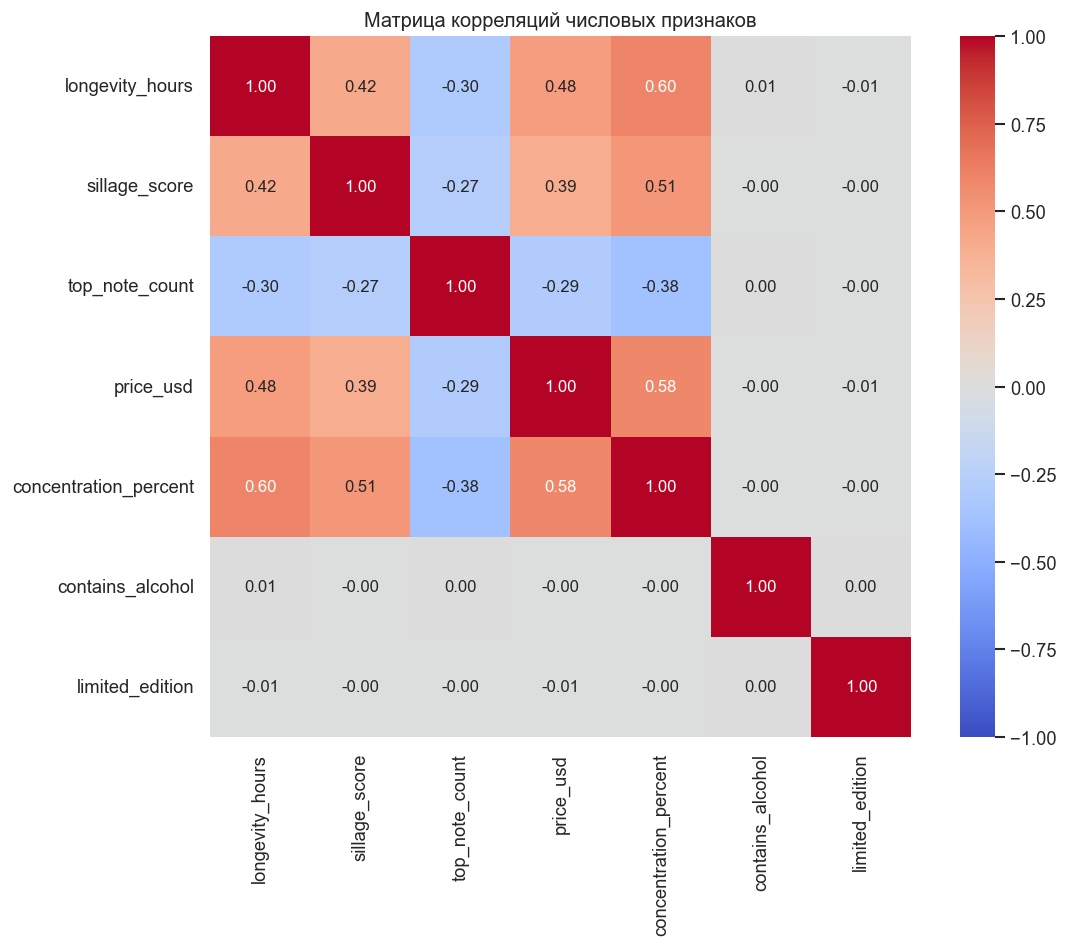

In [10]:
plt.figure(figsize=(10, 8))
corr = df_vis[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Матрица корреляций числовых признаков")
save_figure("fig02_corr.png")
plt.show()

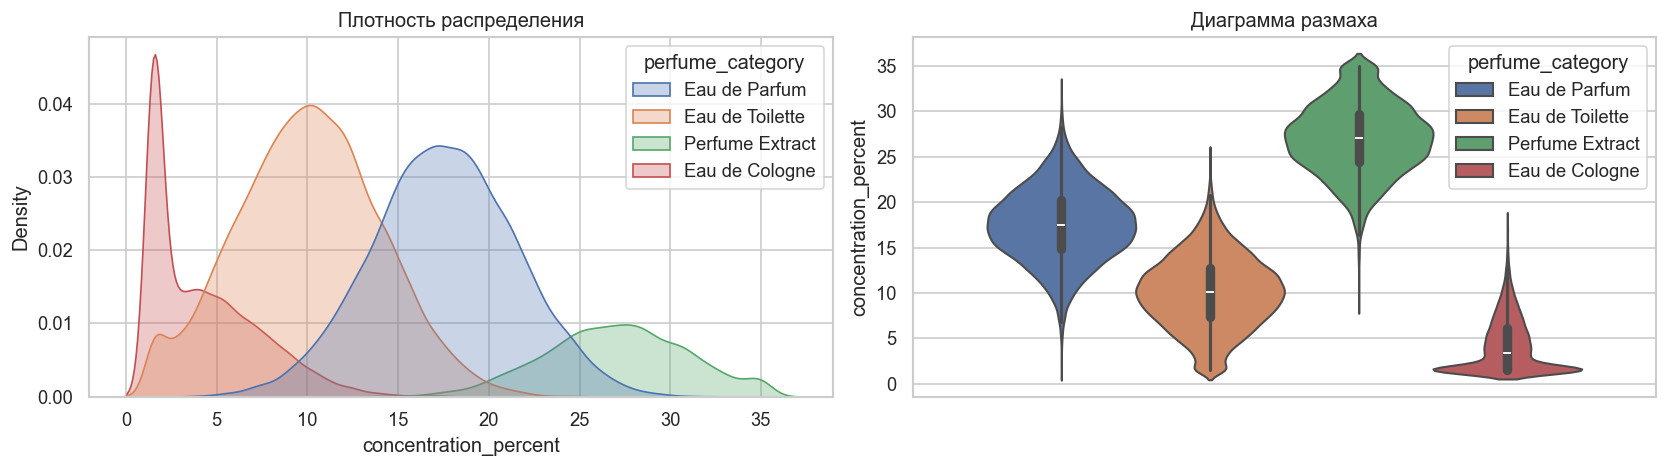

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(
    data=df_vis,
    x="concentration_percent",
    hue="perfume_category",
    fill=True,
    alpha=0.3,
    ax=axes[0],
)
sns.violinplot(
    data=df_vis,
    y="concentration_percent",
    hue="perfume_category",
    ax=axes[1],
)
axes[0].set_title("Плотность распределения")
axes[1].set_title("Диаграмма размаха")
save_figure("fig04_concentration.png")
plt.show()

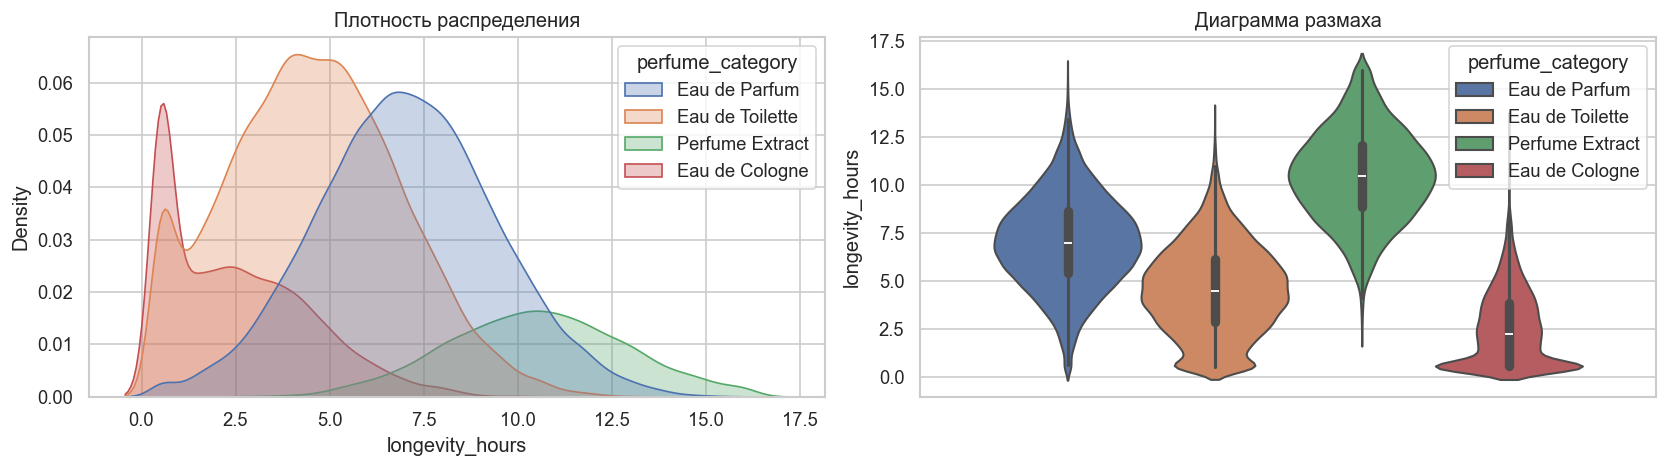

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(
    data=df_vis,
    x="longevity_hours",
    hue="perfume_category",
    fill=True,
    alpha=0.3,
    ax=axes[0],
)
sns.violinplot(
    data=df_vis,
    y="longevity_hours",
    hue="perfume_category",
    ax=axes[1],
)
axes[0].set_title("Плотность распределения")
axes[1].set_title("Диаграмма размаха")
save_figure("fig05_longevity.png")
plt.show()

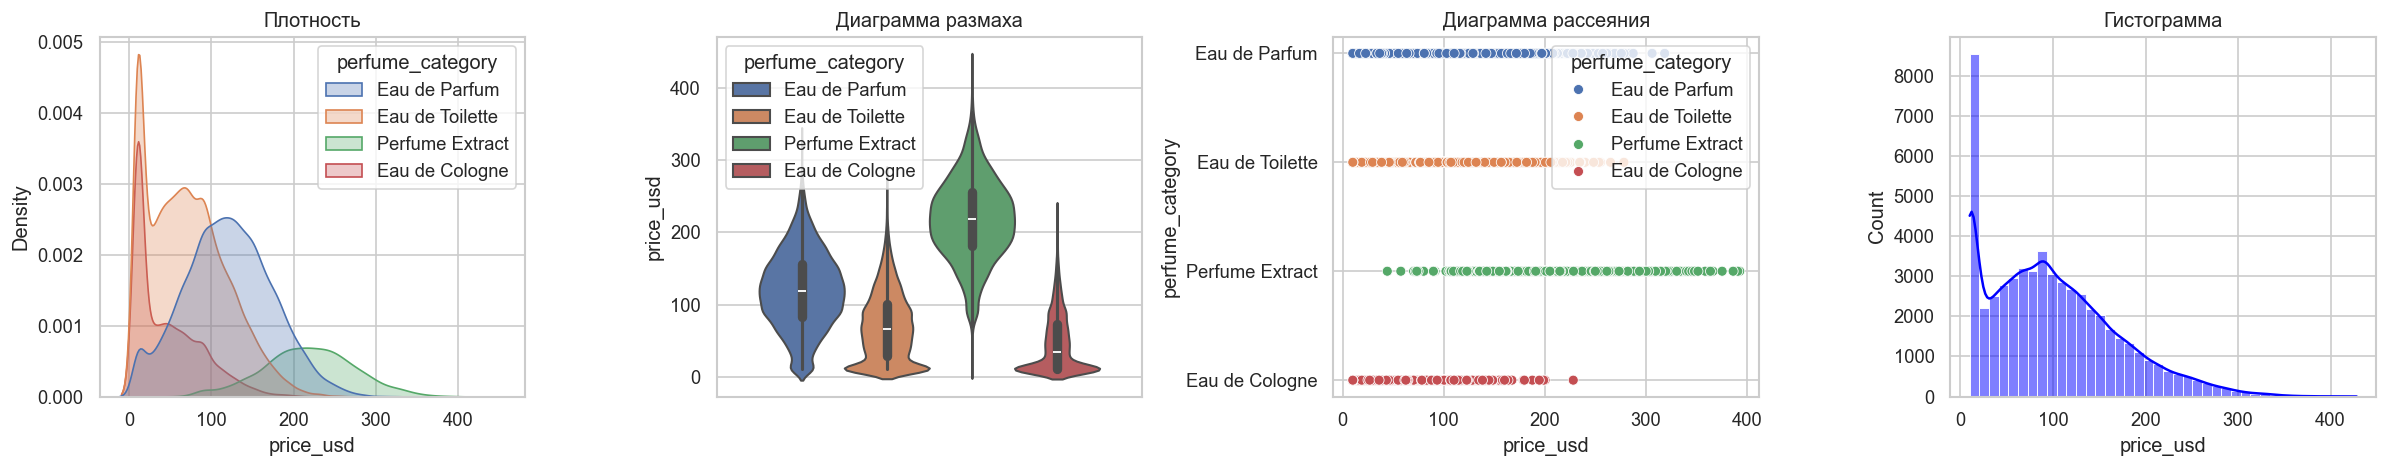

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.kdeplot(
    data=df_vis,
    x="price_usd",
    hue="perfume_category",
    fill=True,
    alpha=0.3,
    ax=axes[0],
)
sns.violinplot(
    data=df_vis,
    y="price_usd",
    hue="perfume_category",
    ax=axes[1],
)
sns.scatterplot(
    data=df_vis.sample(10000, random_state=RANDOM_STATE),
    x="price_usd",
    y="perfume_category",
    hue="perfume_category",
    ax=axes[2],
)
sns.histplot(data=df_vis, x="price_usd", kde=True, bins=40, color="blue", ax=axes[3])
axes[0].set_title("Плотность")
axes[1].set_title("Диаграмма размаха")
axes[2].set_title("Диаграмма рассеяния")
axes[3].set_title("Гистограмма")
save_figure("fig06_price.png")
plt.show()

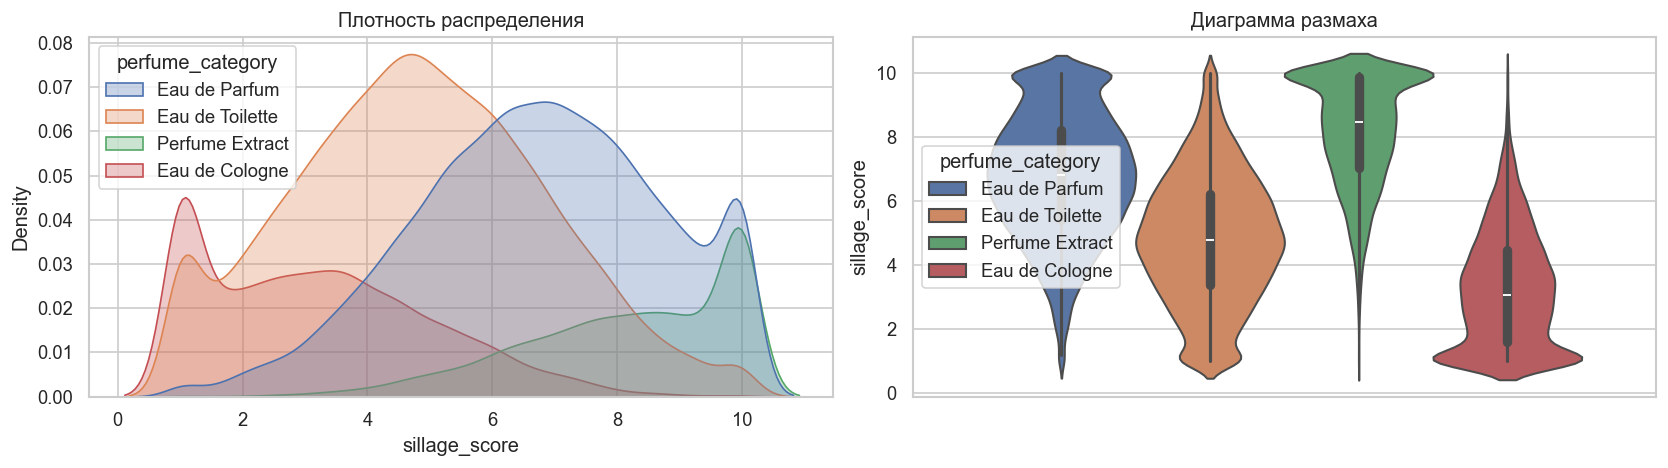

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(
    data=df_vis,
    x="sillage_score",
    hue="perfume_category",
    fill=True,
    alpha=0.3,
    ax=axes[0],
)
sns.violinplot(
    data=df_vis,
    y="sillage_score",
    hue="perfume_category",
    ax=axes[1],
)
axes[0].set_title("Плотность распределения")
axes[1].set_title("Диаграмма размаха")
save_figure("fig07_sillage.png")
plt.show()

### Подготовка признаков

In [15]:
categorical_pipe = Pipeline(
    steps=[
        ("cat_imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("one_hot_encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
numerical_pipe = Pipeline(
    steps=[
        ("num_imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("cat_tf", categorical_pipe, cat_cols),
        ("num_tf", numerical_pipe, num_cols),
    ]
)
X_scaled = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

RESULTS["dataset"] = {
    "n_rows_raw": n_rows_raw,
    "n_rows": int(df.shape[0]),
    "n_features_raw": int(X.shape[1]),
    "n_features_encoded": int(X_scaled.shape[1]),
    "n_duplicates": n_duplicates,
    "missing_raw": {key: int(value) for key, value in missing_raw.items()},
    "missing_clean": {key: int(value) for key, value in missing_clean.items()},
    "target_counts": {
        key: int(value) for key, value in df["perfume_category"].value_counts().items()
    },
    "pca_evr": [float(value) for value in pca.explained_variance_ratio_],
}

print("Размерность матрицы признаков:", X_scaled.shape)
print(
    "Доля объяснённой дисперсии PCA:",
    pca.explained_variance_ratio_,
    "сумма:",
    pca.explained_variance_ratio_.sum(),
)

Размерность матрицы признаков: (55000, 20)
Доля объяснённой дисперсии PCA: [0.29700988 0.10934121] сумма: 0.40635108558103405


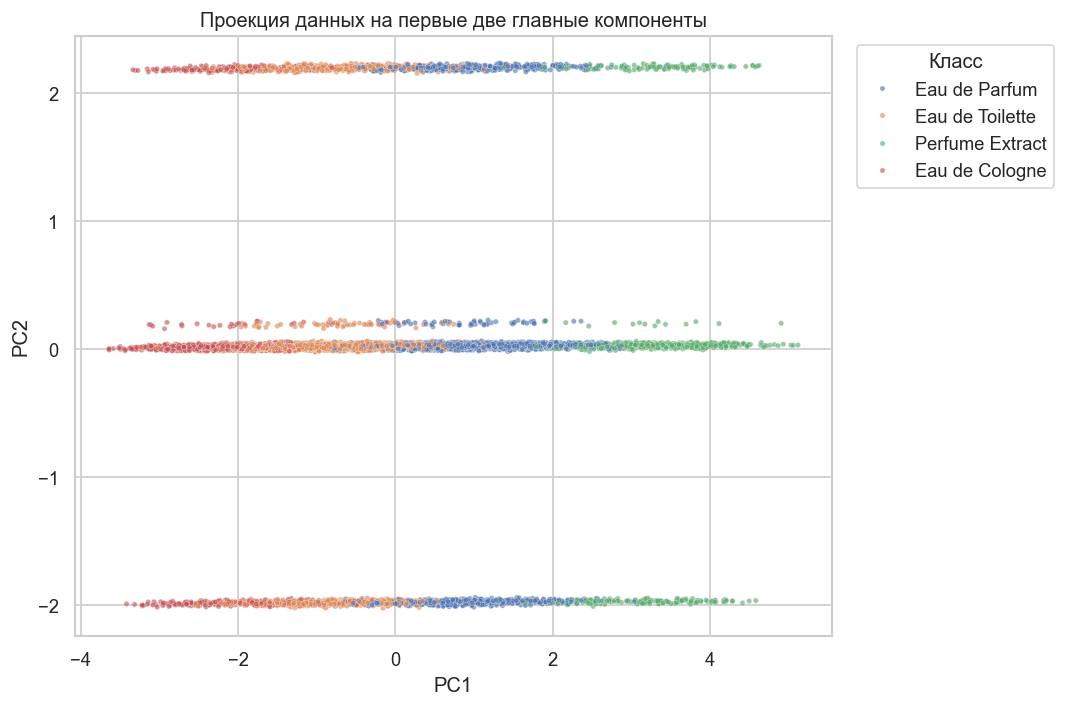

In [16]:
plot_idx = np.random.RandomState(RANDOM_STATE).choice(
    len(X_scaled), size=10000, replace=False
)
pca_plot = pd.DataFrame(
    {
        "PC1": X_pca[plot_idx, 0],
        "PC2": X_pca[plot_idx, 1],
        "Класс": y.iloc[plot_idx].to_numpy(),
    }
)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_plot, x="PC1", y="PC2", hue="Класс", s=10, alpha=0.6)
plt.title("Проекция данных на первые две главные компоненты")
plt.legend(title="Класс", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("fig08_pca_true.png")
plt.show()

## 2. Обучение моделей кластеризации

### a. Метод K-средних

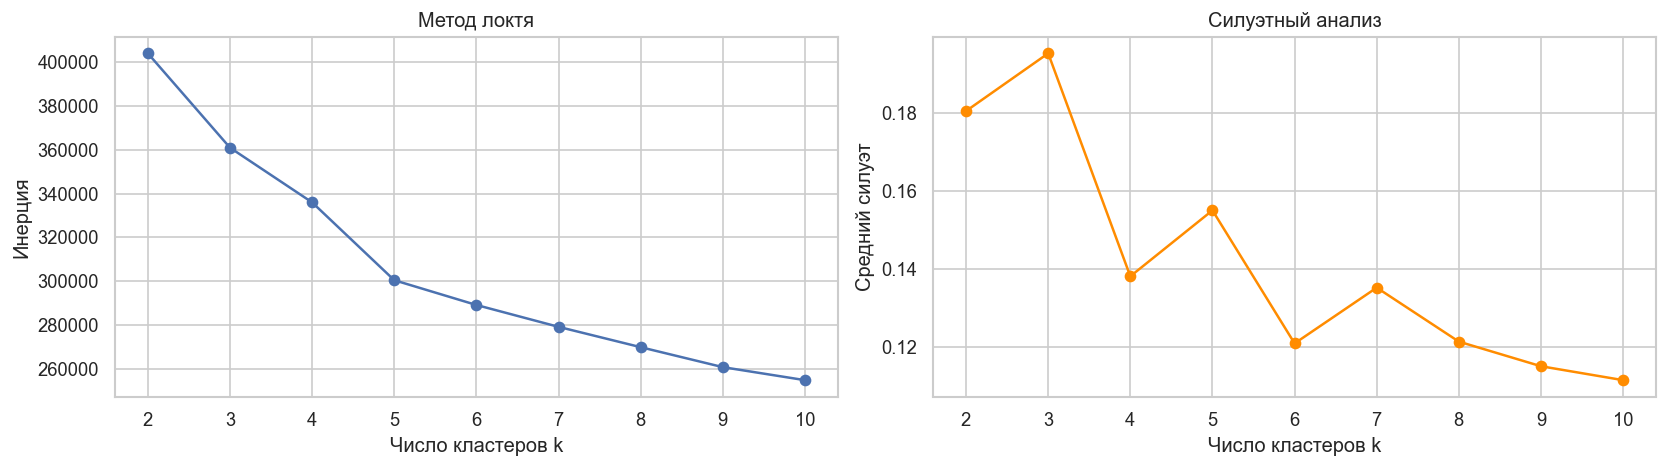

,k,inertia,silhouette,ari,nmi
0,2,404186.911166,0.180569,0.384225,0.428347
1,3,361024.151126,0.195354,0.318037,0.335048
2,4,336002.288223,0.138206,0.321573,0.406583
3,5,300395.409986,0.155106,0.267947,0.346146
4,6,289067.377387,0.121004,0.255026,0.331919
5,7,279065.219630,0.135298,0.178817,0.310813
6,8,269763.536468,0.121462,0.246085,0.336350
7,9,260632.369546,0.115154,0.196143,0.333098
8,10,254679.160143,0.111587,0.180799,0.323512


In [17]:
k_values = list(range(2, 11))
kmeans_rows = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    kmeans_rows.append(
        {
            "k": k,
            "inertia": float(model.inertia_),
            "silhouette": float(
                silhouette_score(
                    X_scaled,
                    labels,
                    sample_size=10000,
                    random_state=RANDOM_STATE,
                )
            ),
            "ari": float(adjusted_rand_score(y, labels)),
            "nmi": float(normalized_mutual_info_score(y, labels)),
        }
    )
kmeans_df = pd.DataFrame(kmeans_rows)
RESULTS["kmeans"] = kmeans_rows

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(kmeans_df["k"], kmeans_df["inertia"], marker="o")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("Число кластеров k")
axes[0].set_ylabel("Инерция")
axes[1].plot(kmeans_df["k"], kmeans_df["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Силуэтный анализ")
axes[1].set_xlabel("Число кластеров k")
axes[1].set_ylabel("Средний силуэт")
save_figure("fig09_elbow.png")
plt.show()
kmeans_df

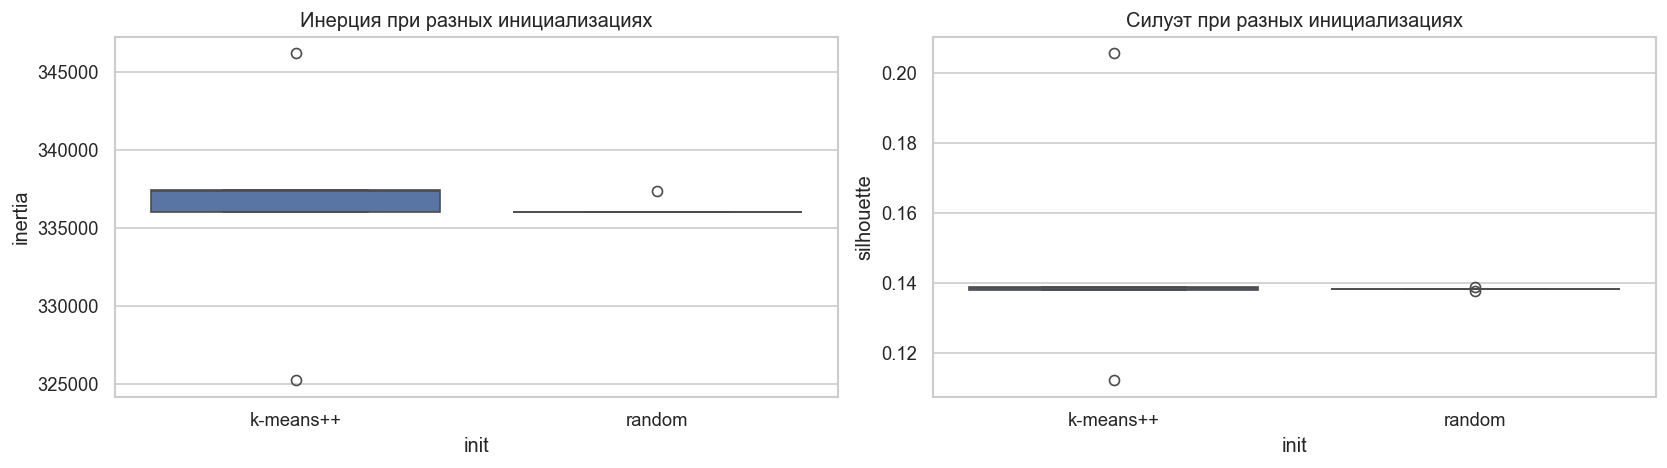

,init,inertia_mean,inertia_std,silhouette_mean,silhouette_std,ari_mean,ari_std
0,k-means++,336454.607925,7453.197491,0.146556,0.034835,0.292991,0.035026
1,random,336283.647844,628.702115,0.138224,0.000366,0.320483,0.005165


In [18]:
init_rows = []
for init in ["k-means++", "random"]:
    for seed in range(5):
        model = KMeans(n_clusters=4, init=init, n_init=1, random_state=seed)
        labels = model.fit_predict(X_scaled)
        init_rows.append(
            {
                "init": init,
                "seed": seed,
                "inertia": float(model.inertia_),
                "silhouette": float(
                    silhouette_score(
                        X_scaled,
                        labels,
                        sample_size=10000,
                        random_state=RANDOM_STATE,
                    )
                ),
                "ari": float(adjusted_rand_score(y, labels)),
            }
        )
init_df = pd.DataFrame(init_rows)
RESULTS["init"] = init_rows

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=init_df, x="init", y="inertia", ax=axes[0])
axes[0].set_title("Инерция при разных инициализациях")
sns.boxplot(data=init_df, x="init", y="silhouette", ax=axes[1])
axes[1].set_title("Силуэт при разных инициализациях")
save_figure("fig10_init.png")
plt.show()

init_summary = (
    init_df.groupby("init")
    .agg(
        inertia_mean=("inertia", "mean"),
        inertia_std=("inertia", "std"),
        silhouette_mean=("silhouette", "mean"),
        silhouette_std=("silhouette", "std"),
        ari_mean=("ari", "mean"),
        ari_std=("ari", "std"),
    )
    .reset_index()
)
RESULTS["init_summary"] = init_summary.to_dict(orient="records")
init_summary

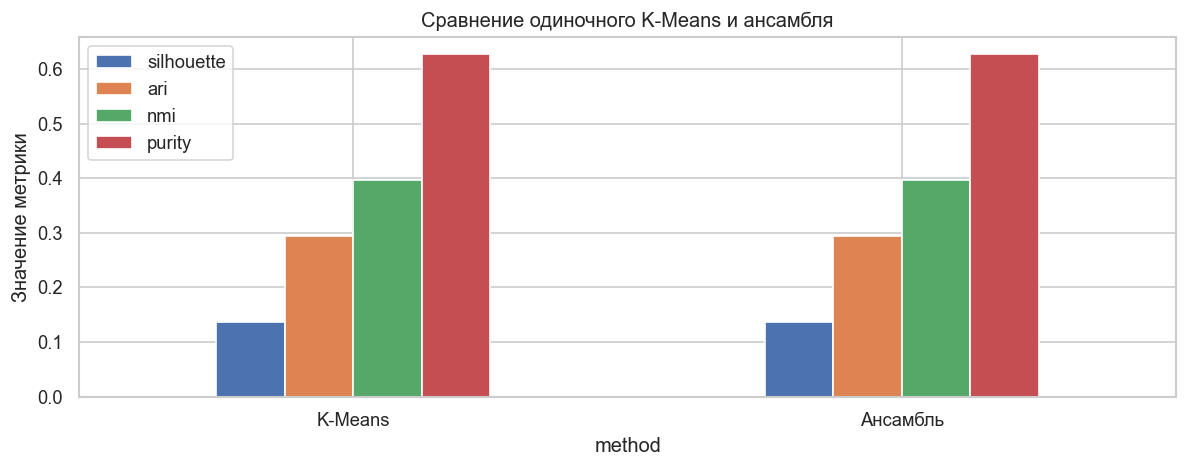

,method,n_clusters,noise_fraction,ari,nmi,purity,silhouette
0,K-Means,4,0.0,0.295390,0.398109,0.6282,0.137536
1,Ансамбль,4,0.0,0.295172,0.397945,0.6280,0.137487


In [19]:
rng = np.random.RandomState(RANDOM_STATE)
ensemble_idx = rng.choice(len(X_scaled), size=5000, replace=False)
X_ensemble = X_scaled[ensemble_idx]
y_ensemble = y.iloc[ensemble_idx].reset_index(drop=True)

ensemble_runs = []
for seed in range(20):
    model = KMeans(n_clusters=4, init="random", n_init=1, random_state=seed)
    ensemble_runs.append(model.fit_predict(X_ensemble))

coassoc = np.zeros((len(X_ensemble), len(X_ensemble)), dtype=np.float32)
for labels in ensemble_runs:
    coassoc += (labels[:, None] == labels[None, :]).astype(np.float32)
coassoc /= len(ensemble_runs)

ensemble_labels = AgglomerativeClustering(
    n_clusters=4,
    metric="precomputed",
    linkage="average",
).fit_predict(1 - coassoc)

single_model = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=RANDOM_STATE)
single_labels = single_model.fit_predict(X_ensemble)


def clustering_metrics(X_data, labels, y_true):
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    result = {
        "n_clusters": int(n_clusters),
        "noise_fraction": float((labels == -1).mean()),
        "ari": float(adjusted_rand_score(y_true, labels)),
        "nmi": float(normalized_mutual_info_score(y_true, labels)),
        "purity": float(purity_score(np.asarray(y_true)[mask], labels[mask])),
    }
    if n_clusters > 1 and mask.sum() > 1:
        result["silhouette"] = float(
            silhouette_score(
                X_data[mask],
                labels[mask],
                sample_size=min(10000, int(mask.sum())),
                random_state=RANDOM_STATE,
            )
        )
    else:
        result["silhouette"] = float("nan")
    return result


ensemble_comparison = pd.DataFrame(
    [
        {"method": "K-Means", **clustering_metrics(X_ensemble, single_labels, y_ensemble)},
        {"method": "Ансамбль", **clustering_metrics(X_ensemble, ensemble_labels, y_ensemble)},
    ]
)
pairwise_ensemble = [
    adjusted_rand_score(ensemble_runs[i], ensemble_runs[j])
    for i in range(len(ensemble_runs))
    for j in range(i + 1, len(ensemble_runs))
]
RESULTS["ensemble"] = {
    "metrics": ensemble_comparison.to_dict(orient="records"),
    "pairwise_ari_mean": float(np.mean(pairwise_ensemble)),
    "pairwise_ari_std": float(np.std(pairwise_ensemble)),
}

ensemble_comparison.set_index("method")[["silhouette", "ari", "nmi", "purity"]].plot(
    kind="bar", figsize=(10, 4), rot=0
)
plt.title("Сравнение одиночного K-Means и ансамбля")
plt.ylabel("Значение метрики")
save_figure("fig11_ensemble.png")
plt.show()
ensemble_comparison

### b. DBSCAN

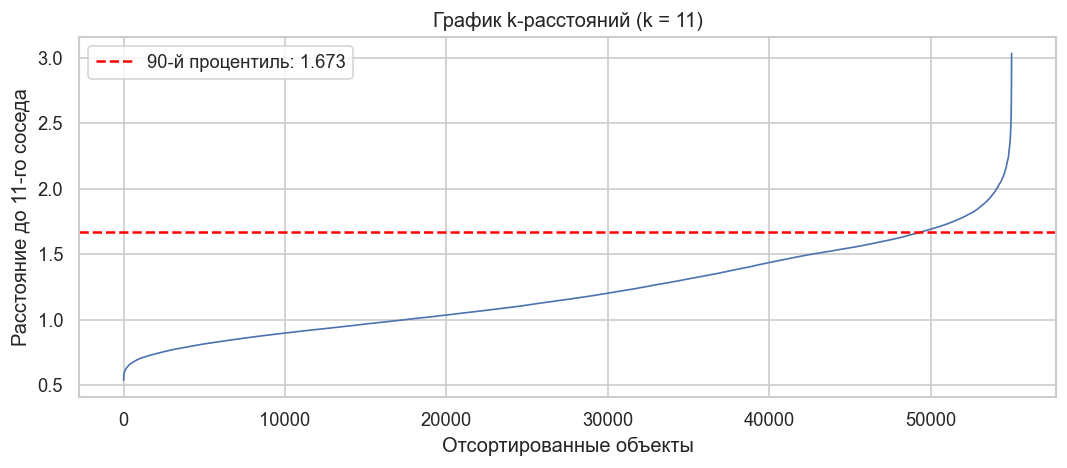

90-й процентиль: 1.6726865771737993


In [20]:
min_samples = 11
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
kdist = np.sort(distances[:, -1])
eps_quantile = float(np.quantile(kdist, 0.90))

plt.figure(figsize=(9, 4))
plt.plot(kdist, linewidth=1)
plt.axhline(
    eps_quantile,
    color="red",
    linestyle="--",
    label=f"90-й процентиль: {eps_quantile:.3f}",
)
plt.title("График k-расстояний (k = 11)")
plt.xlabel("Отсортированные объекты")
plt.ylabel("Расстояние до 11-го соседа")
plt.legend()
save_figure("fig12_kdist.png")
plt.show()

RESULTS["kdist"] = {
    "quantiles": {
        str(quantile): float(np.quantile(kdist, quantile))
        for quantile in [0.5, 0.8, 0.9, 0.95, 0.99]
    },
    "max": float(kdist[-1]),
}
print("90-й процентиль:", eps_quantile)

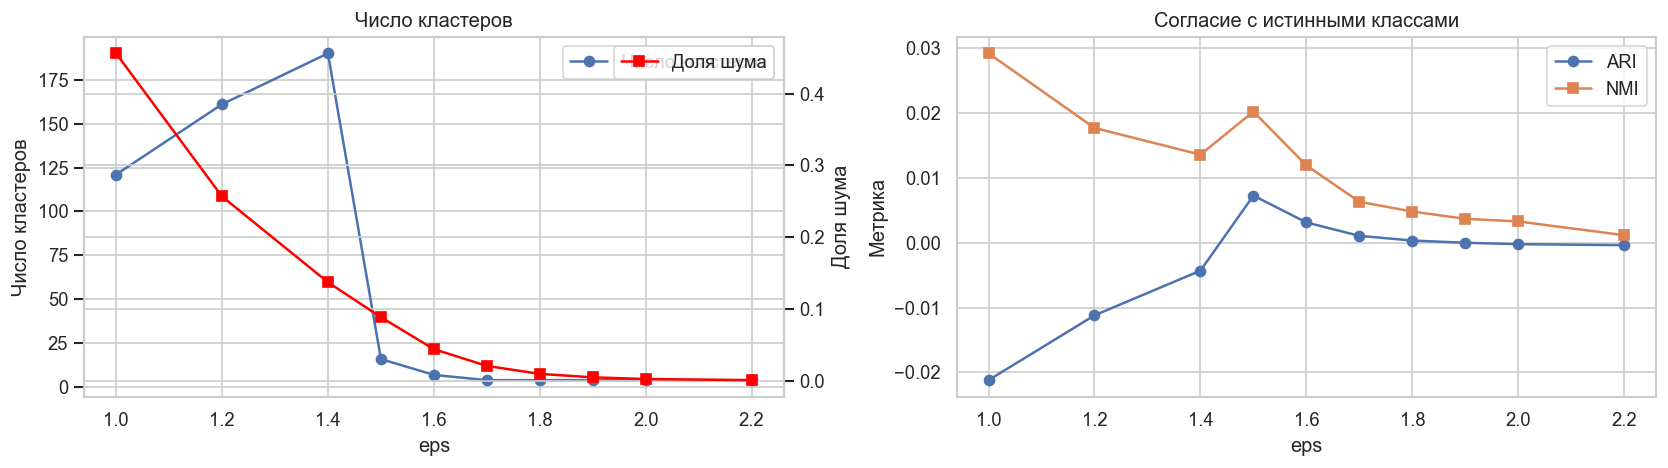

,eps,n_clusters,noise_fraction,ari,nmi,silhouette
0,1.0,121,0.455982,-0.021201,0.029244,-0.077063
1,1.2,161,0.256636,-0.011200,0.017732,-0.070607
2,1.4,190,0.137091,-0.004299,0.013600,-0.043369
3,1.5,16,0.088436,0.007286,0.020253,0.020221
4,1.6,7,0.043873,0.003145,0.011948,0.199307
5,1.7,4,0.020545,0.001073,0.006334,0.213466
6,1.8,4,0.009436,0.000348,0.004823,0.214070
7,1.9,4,0.004618,0.000006,0.003700,0.216602
8,2.0,4,0.002291,-0.000212,0.003296,0.218176
9,2.2,4,0.000691,-0.000365,0.001175,0.216155


In [21]:
eps_values = [1.0, 1.2, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.2]
dbscan_rows = []
for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    row = {
        "eps": eps,
        "n_clusters": int(n_clusters),
        "noise_fraction": float((labels == -1).mean()),
        "ari": float(adjusted_rand_score(y, labels)),
        "nmi": float(normalized_mutual_info_score(y, labels)),
    }
    if n_clusters > 1 and mask.sum() > 1:
        row["silhouette"] = float(
            silhouette_score(
                X_scaled[mask],
                labels[mask],
                sample_size=min(10000, int(mask.sum())),
                random_state=RANDOM_STATE,
            )
        )
    else:
        row["silhouette"] = float("nan")
    dbscan_rows.append(row)
dbscan_df = pd.DataFrame(dbscan_rows)
RESULTS["dbscan_eps"] = dbscan_rows

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(dbscan_df["eps"], dbscan_df["n_clusters"], marker="o", label="Число кластеров")
axes[0].set_xlabel("eps")
axes[0].set_ylabel("Число кластеров")
axes[0].set_title("Число кластеров")
noise_axis = axes[0].twinx()
noise_axis.plot(
    dbscan_df["eps"],
    dbscan_df["noise_fraction"],
    marker="s",
    color="red",
    label="Доля шума",
)
noise_axis.set_ylabel("Доля шума")
axes[0].legend(loc="upper right")
noise_axis.legend(loc="upper right")
axes[1].plot(dbscan_df["eps"], dbscan_df["ari"], marker="o", label="ARI")
axes[1].plot(dbscan_df["eps"], dbscan_df["nmi"], marker="s", label="NMI")
axes[1].set_xlabel("eps")
axes[1].set_ylabel("Метрика")
axes[1].set_title("Согласие с истинными классами")
axes[1].legend()
save_figure("fig13_dbscan_sens.png")
plt.show()
dbscan_df

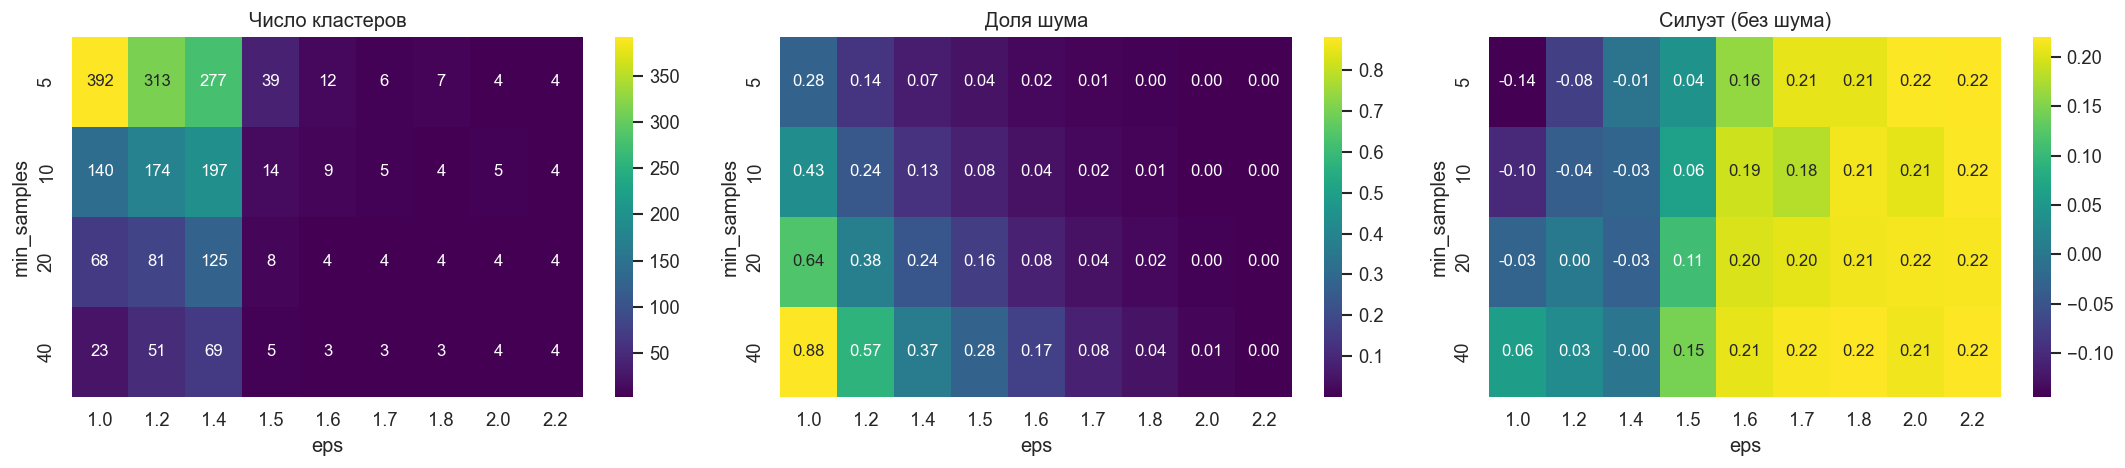

,min_samples,eps,n_clusters,noise_fraction,ari,nmi,silhouette
0,5,1.0,392,0.278091,-0.010313,0.028202,-0.143733
1,5,1.2,313,0.137055,-0.003463,0.017340,-0.076745
2,5,1.4,277,0.066727,-0.000753,0.011427,-0.005226
3,5,1.5,39,0.042036,0.003382,0.013399,0.041757
4,5,1.6,12,0.020745,0.001150,0.006189,0.160702
5,5,1.7,6,0.009182,0.000400,0.004600,0.206247
6,5,1.8,7,0.004455,0.000074,0.003559,0.205885
7,5,2.0,4,0.001145,-0.000290,0.001423,0.217622
8,5,2.2,4,0.000327,-0.000380,0.000519,0.219980
9,10,1.0,140,0.431036,-0.019928,0.028575,-0.103875


In [22]:
grid_min_samples = [5, 10, 20, 40]
grid_eps = [1.0, 1.2, 1.4, 1.5, 1.6, 1.7, 1.8, 2.0, 2.2]
grid_rows = []
for grid_ms in grid_min_samples:
    for grid_eps_value in grid_eps:
        labels = DBSCAN(eps=grid_eps_value, min_samples=grid_ms).fit_predict(X_scaled)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        row = {
            "min_samples": grid_ms,
            "eps": grid_eps_value,
            "n_clusters": int(n_clusters),
            "noise_fraction": float((labels == -1).mean()),
            "ari": float(adjusted_rand_score(y, labels)),
            "nmi": float(normalized_mutual_info_score(y, labels)),
        }
        if n_clusters > 1 and mask.sum() > 1:
            row["silhouette"] = float(
                silhouette_score(
                    X_scaled[mask],
                    labels[mask],
                    sample_size=min(10000, int(mask.sum())),
                    random_state=RANDOM_STATE,
                )
            )
        else:
            row["silhouette"] = float("nan")
        grid_rows.append(row)
grid_df = pd.DataFrame(grid_rows)
RESULTS["dbscan_grid"] = grid_rows

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for axis, value, title, fmt in [
    (axes[0], "n_clusters", "Число кластеров", ".0f"),
    (axes[1], "noise_fraction", "Доля шума", ".2f"),
    (axes[2], "silhouette", "Силуэт (без шума)", ".2f"),
]:
    pivot = grid_df.pivot(index="min_samples", columns="eps", values=value)
    sns.heatmap(pivot, annot=True, fmt=fmt, cmap="viridis", ax=axis)
    axis.set_title(title)
    axis.set_xlabel("eps")
    axis.set_ylabel("min_samples")
save_figure("fig13b_dbscan_grid.png")
plt.show()
grid_df

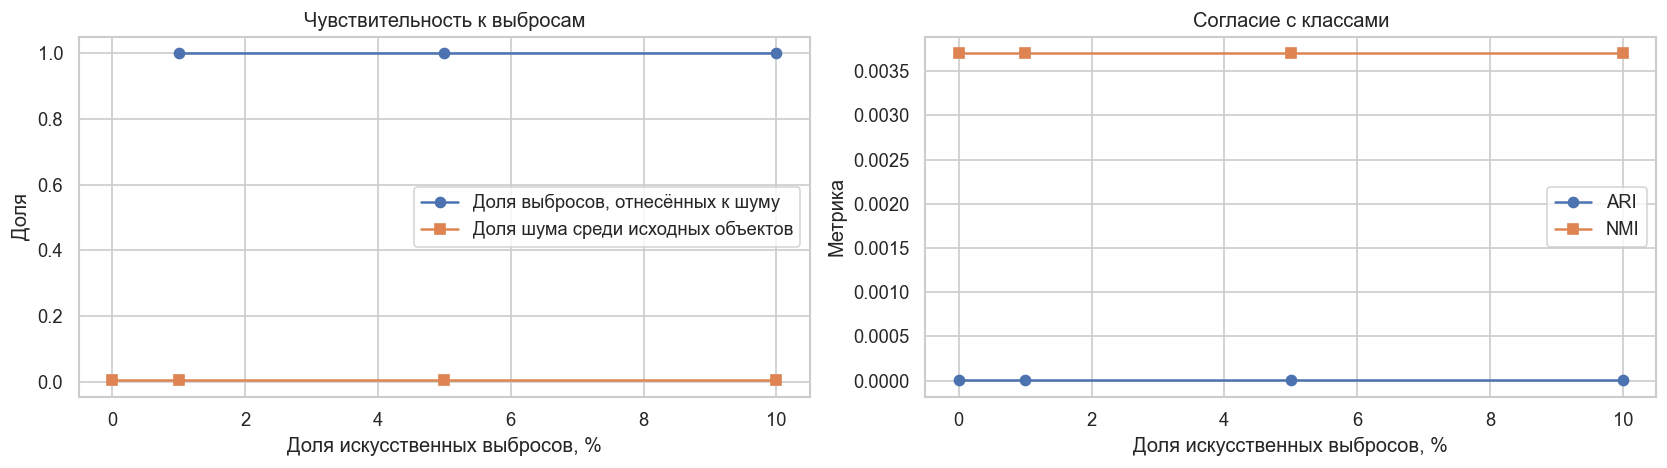

,contamination,n_outliers,outlier_noise_recall,original_noise_fraction,n_clusters,ari_original,nmi_original
0,0.00,0,NaN,0.004618,4,0.000006,0.0037
1,0.01,550,1.0,0.004618,4,0.000006,0.0037
2,0.05,2750,1.0,0.004618,4,0.000006,0.0037
3,0.10,5500,1.0,0.004618,4,0.000006,0.0037


In [23]:
eps_final = 1.9
contamination_levels = [0.0, 0.01, 0.05, 0.10]
outlier_rows = []
rng = np.random.RandomState(RANDOM_STATE)
for contamination in contamination_levels:
    n_outliers = int(contamination * len(X_scaled))
    outliers = rng.uniform(-10, 10, size=(n_outliers, X_scaled.shape[1]))
    X_contaminated = np.vstack([X_scaled, outliers]) if n_outliers else X_scaled
    labels = DBSCAN(eps=eps_final, min_samples=min_samples).fit_predict(X_contaminated)
    original_labels = labels[: len(X_scaled)]
    outlier_noise_recall = (
        float((labels[len(X_scaled):] == -1).mean()) if n_outliers else float("nan")
    )
    outlier_rows.append(
        {
            "contamination": contamination,
            "n_outliers": n_outliers,
            "outlier_noise_recall": outlier_noise_recall,
            "original_noise_fraction": float((original_labels == -1).mean()),
            "n_clusters": int(len(set(original_labels[original_labels != -1]))),
            "ari_original": float(adjusted_rand_score(y, original_labels)),
            "nmi_original": float(normalized_mutual_info_score(y, original_labels)),
        }
    )
outlier_df = pd.DataFrame(outlier_rows)
RESULTS["dbscan_noise"] = outlier_rows

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(
    outlier_df["contamination"] * 100,
    outlier_df["outlier_noise_recall"],
    marker="o",
    label="Доля выбросов, отнесённых к шуму",
)
axes[0].plot(
    outlier_df["contamination"] * 100,
    outlier_df["original_noise_fraction"],
    marker="s",
    label="Доля шума среди исходных объектов",
)
axes[0].set_xlabel("Доля искусственных выбросов, %")
axes[0].set_ylabel("Доля")
axes[0].set_title("Чувствительность к выбросам")
axes[0].legend()
axes[1].plot(outlier_df["contamination"] * 100, outlier_df["ari_original"], marker="o", label="ARI")
axes[1].plot(outlier_df["contamination"] * 100, outlier_df["nmi_original"], marker="s", label="NMI")
axes[1].set_xlabel("Доля искусственных выбросов, %")
axes[1].set_ylabel("Метрика")
axes[1].set_title("Согласие с классами")
axes[1].legend()
save_figure("fig14_dbscan_noise.png")
plt.show()
outlier_df

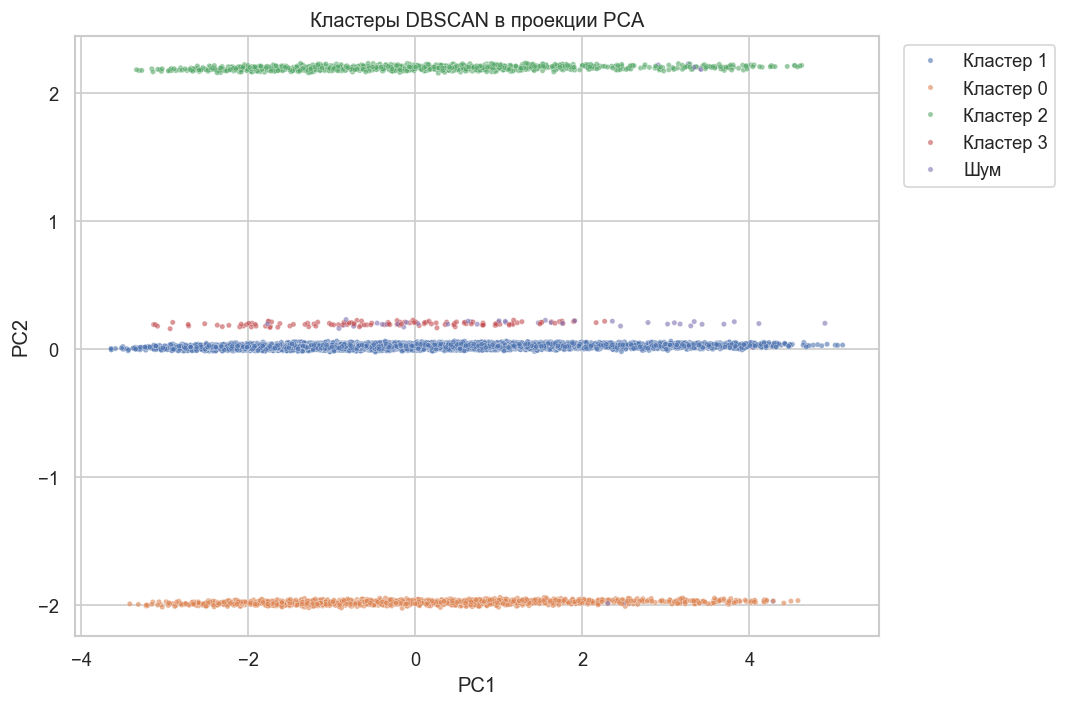

{'eps': 1.9,
 'min_samples': 11,
 'n_clusters': 4,
 'noise_fraction': 0.004618181818181818,
 'ari': 6.033185265313745e-06,
 'nmi': 0.003699993882588349,
 'purity': 0.4014905198553319,
 'silhouette': 0.2166019471088407}

In [24]:
dbscan_labels = DBSCAN(eps=eps_final, min_samples=min_samples).fit_predict(X_scaled)
dbscan_mask = dbscan_labels != -1 # excepting the noise one
dbscan_metrics = {
    "eps": eps_final,
    "min_samples": min_samples,
    "n_clusters": int(len(set(dbscan_labels[dbscan_mask]))),
    "noise_fraction": float((dbscan_labels == -1).mean()),
    "ari": float(adjusted_rand_score(y, dbscan_labels)),
    "nmi": float(normalized_mutual_info_score(y, dbscan_labels)),
    "purity": float(purity_score(np.asarray(y)[dbscan_mask], dbscan_labels[dbscan_mask])),
}
if dbscan_metrics["n_clusters"] > 1:
    dbscan_metrics["silhouette"] = float(
        silhouette_score(
            X_scaled[dbscan_mask],
            dbscan_labels[dbscan_mask],
            sample_size=min(10000, int(dbscan_mask.sum())),
            random_state=RANDOM_STATE,
        )
    )
else:
    dbscan_metrics["silhouette"] = float("nan")
RESULTS["dbscan_final"] = dbscan_metrics

dbscan_plot = pd.DataFrame(
    {
        "PC1": X_pca[plot_idx, 0],
        "PC2": X_pca[plot_idx, 1],
        "Кластер": np.where(
            dbscan_labels[plot_idx] == -1,
            "Шум",
            np.char.add("Кластер ", dbscan_labels[plot_idx].astype(str)),
        ),
    }
)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=dbscan_plot, x="PC1", y="PC2", hue="Кластер", s=10, alpha=0.6)
plt.title("Кластеры DBSCAN в проекции PCA")
plt.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("fig15_dbscan_pca.png")
plt.show()
dbscan_metrics

In [25]:
pd.crosstab(dbscan_labels, y)


perfume_category,Eau de Cologne,Eau de Parfum,Eau de Toilette,Perfume Extract
row_0,,,,
-1,9,79,34,132
0,1030,2441,2784,663
1,6201,14500,16490,4114
2,868,1962,2366,552
3,150,272,340,13


### c. Иерархическая кластеризация

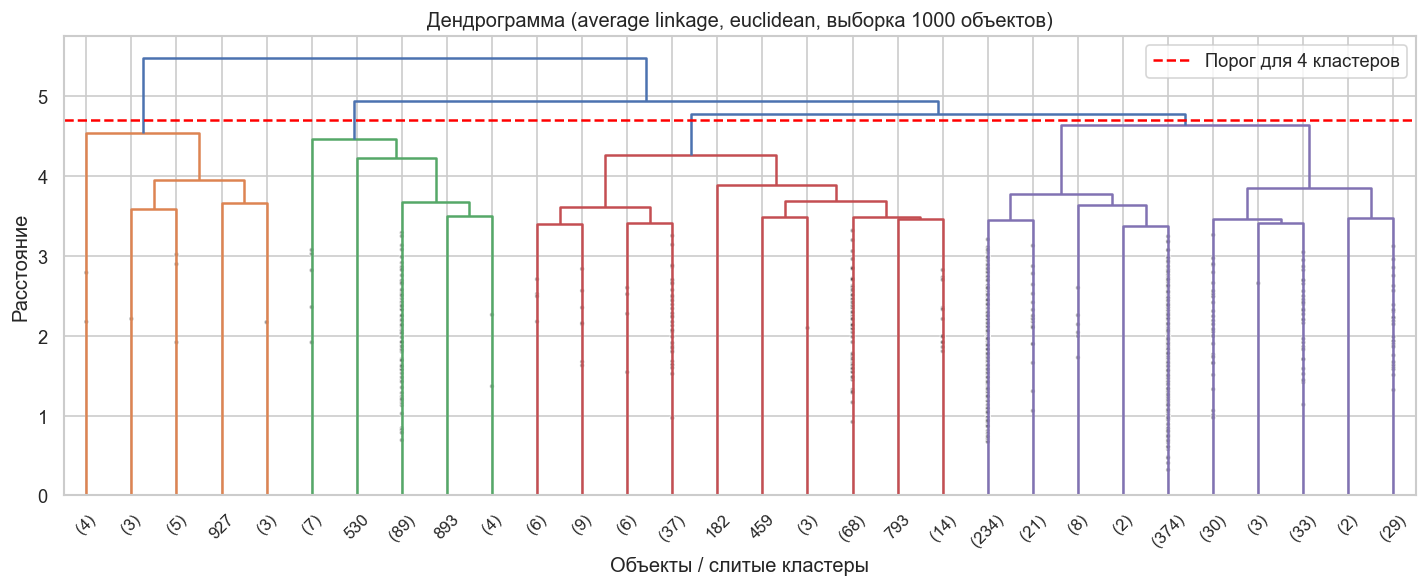

In [26]:
hier_idx = np.random.RandomState(RANDOM_STATE).choice(
    len(X_scaled), size=1000, replace=False
)
X_hier = X_scaled[hier_idx]
y_hier = y.iloc[hier_idx].reset_index(drop=True)
Z = linkage(X_hier, method="average", metric="euclidean")
color_threshold = (Z[-4, 2] + Z[-3, 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_contracted=True,
    color_threshold=color_threshold,
)
plt.axhline(
    color_threshold,
    color="red",
    linestyle="--",
    label="Порог для 4 кластеров",
)
plt.title("Дендрограмма (average linkage, euclidean, выборка 1000 объектов)")
plt.xlabel("Объекты / слитые кластеры")
plt.ylabel("Расстояние")
plt.legend()
save_figure("fig16_dendrogram.png")
plt.show()

In [27]:
hier_configs = [
    ("average", "euclidean"), # dist between clusters is avg of all pairs of objects, euclidian distance as a metric
    ("average", "cityblock"), # cityblock - манхеттеновское расстояние, которое считается по сумме abs(difference)
    ("average", "cosine"),    # cosine = ab/(norm(a)*norm(b))
    ("complete", "euclidean"),# from the furthest to a furthest sample, sensitive to outliers
    ("ward", "euclidean"),    # объединяет кластеры так, чтобы минимально увеличить внутрикластерную дисперсию, то есть неделать их размазанными
    ("single", "euclidean"),  # from closest object to closest object
]
hier_rows = []
for method, metric in hier_configs:
    start = time.perf_counter()
    Z_config = linkage(X_hier, method=method, metric=metric)
    labels = fcluster(Z_config, t=4, criterion="maxclust") - 1
    elapsed = time.perf_counter() - start
    row = {
        "linkage": method,
        "metric": metric,
        "time": float(elapsed),
        "n_clusters": int(len(set(labels))),
        "sizes": [int(value) for value in np.bincount(labels)],
        "ari": float(adjusted_rand_score(y_hier, labels)),
        "nmi": float(normalized_mutual_info_score(y_hier, labels)),
    }
    if row["n_clusters"] > 1:
        row["silhouette"] = float(
            silhouette_score(X_hier, labels, random_state=RANDOM_STATE)
        )
    else:
        row["silhouette"] = float("nan")
    hier_rows.append(row)
hier_df = pd.DataFrame(hier_rows)
RESULTS["hierarchical"] = hier_rows
hier_df

,linkage,metric,time,n_clusters,sizes,ari,nmi,silhouette
0,average,euclidean,0.010806,4,"[16, 102, 146, 736]",0.120181,0.186786,0.171961
1,average,cityblock,0.011349,4,"[4, 116, 143, 737]",-0.001448,0.017756,0.192375
2,average,cosine,0.012118,4,"[146, 341, 120, 393]",0.247298,0.248904,0.194409
3,complete,euclidean,0.010415,4,"[152, 221, 70, 557]",0.264754,0.353182,0.113200
4,ward,euclidean,0.013209,4,"[146, 319, 415, 120]",0.230035,0.237139,0.196364
5,single,euclidean,0.006040,4,"[880, 118, 1, 1]",-0.000484,0.008140,0.161339


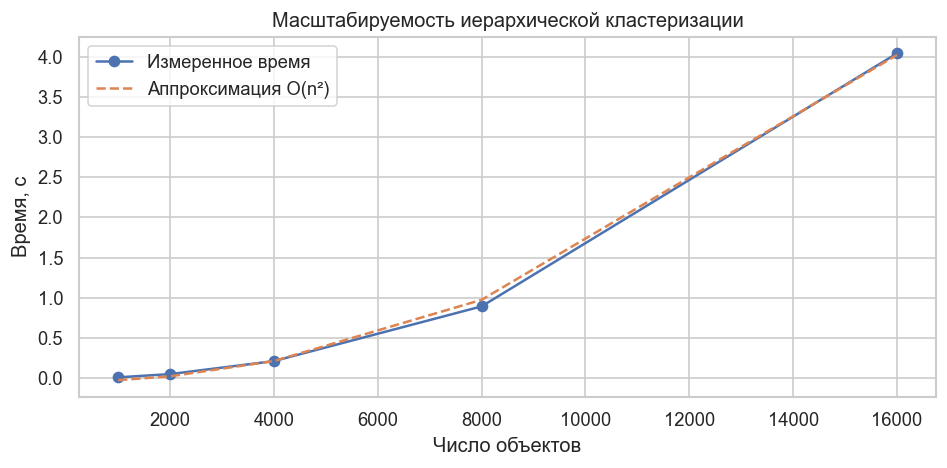

,n,time
0,1000,0.011174
1,2000,0.051264
2,4000,0.212827
3,8000,0.893649
4,16000,4.040959


In [28]:
scale_sizes = [1000, 2000, 4000, 8000, 16000]
scale_rows = []
for n in scale_sizes:
    sample_idx = np.random.RandomState(RANDOM_STATE).choice(
        len(X_scaled), size=n, replace=False
    )
    start = time.perf_counter()
    linkage(X_scaled[sample_idx], method="average", metric="euclidean")
    elapsed = time.perf_counter() - start
    scale_rows.append({"n": n, "time": float(elapsed)})
scale_df = pd.DataFrame(scale_rows)
RESULTS["scalability"] = scale_rows

plt.figure(figsize=(8, 4))
plt.plot(scale_df["n"], scale_df["time"], marker="o", label="Измеренное время")
n_values = scale_df["n"].to_numpy()
t_values = scale_df["time"].to_numpy()
coefficients = np.polyfit(n_values**2, t_values, 1)
plt.plot(
    n_values,
    coefficients[0] * n_values**2 + coefficients[1],
    linestyle="--",
    label="Аппроксимация O(n²)",
)
plt.xlabel("Число объектов")
plt.ylabel("Время, с")
plt.title("Масштабируемость иерархической кластеризации")
plt.legend()
save_figure("fig17_hier_scalability.png")
plt.show()
scale_df

## 3. Оценка моделей

### a. Сравнение разбиений и экспертная оценка

In [29]:
kmeans2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
labels_kmeans2 = kmeans2.fit_predict(X_scaled)
kmeans4 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
labels_kmeans4 = kmeans4.fit_predict(X_scaled)

hier_final_idx = np.random.RandomState(RANDOM_STATE).choice(
    len(X_scaled), size=5000, replace=False
)
X_hier_final = X_scaled[hier_final_idx]
y_hier_final = y.iloc[hier_final_idx].reset_index(drop=True)
Z_final = linkage(X_hier_final, method="complete", metric="euclidean")
labels_hier = fcluster(Z_final, t=4, criterion="maxclust") - 1

comparison_rows = []
comparison_rows.append(
    {"method": "K-Means, k=2", **clustering_metrics(X_scaled, labels_kmeans2, y)}
)
comparison_rows.append(
    {"method": "K-Means, k=4", **clustering_metrics(X_scaled, labels_kmeans4, y)}
)
comparison_rows.append(
    {"method": "DBSCAN", **clustering_metrics(X_scaled, dbscan_labels, y)}
)
comparison_rows.append(
    {
        "method": "Иерархическая (complete, 5000)",
        **clustering_metrics(X_hier_final, labels_hier, y_hier_final),
    }
)
comparison_rows.append(
    {
        "method": "Ансамбль K-Means (5000)",
        **clustering_metrics(X_ensemble, ensemble_labels, y_ensemble),
    }
)
comparison_df = pd.DataFrame(comparison_rows)
RESULTS["comparison"] = comparison_rows
comparison_df

,method,n_clusters,noise_fraction,ari,nmi,purity,silhouette
0,"K-Means, k=2",2,0.000000,0.384225,0.428347,0.661018,0.180569
1,"K-Means, k=4",4,0.000000,0.321573,0.406583,0.642218,0.138206
2,DBSCAN,4,0.004618,0.000006,0.003700,0.401491,0.216602
3,"Иерархическая (complete, 5000)",4,0.000000,0.211810,0.248507,0.584200,0.176063
4,Ансамбль K-Means (5000),4,0.000000,0.295172,0.397945,0.628000,0.137487


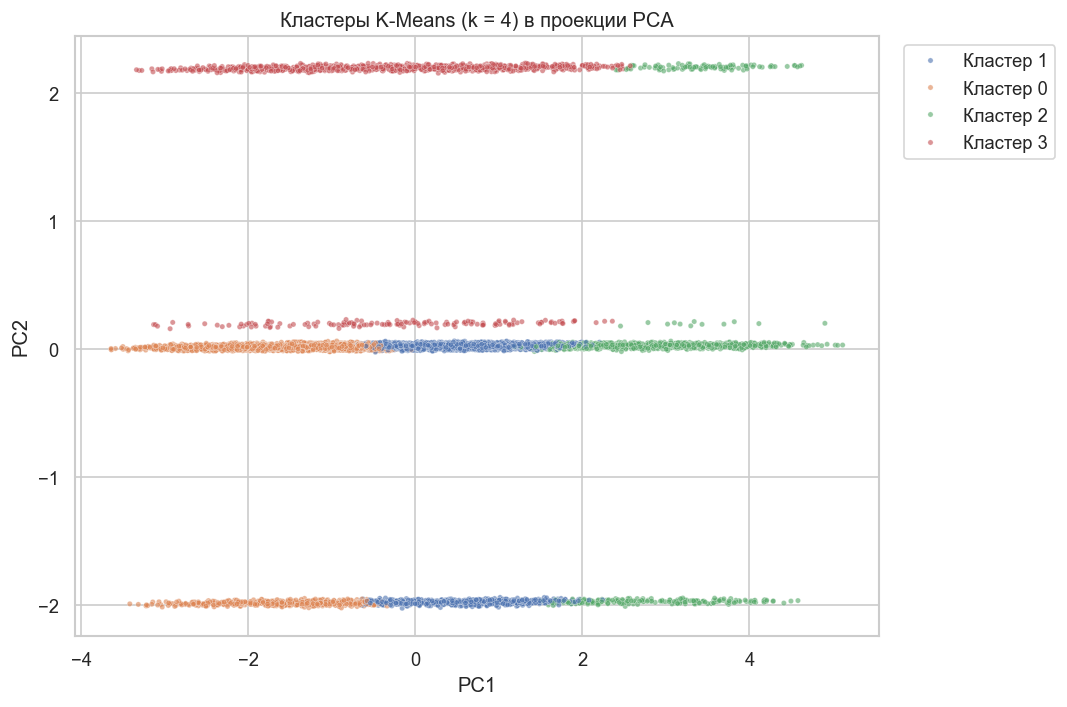

In [30]:
kmeans_plot = pd.DataFrame(
    {
        "PC1": X_pca[plot_idx, 0],
        "PC2": X_pca[plot_idx, 1],
        "Кластер": np.char.add("Кластер ", labels_kmeans4[plot_idx].astype(str)),
    }
)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=kmeans_plot, x="PC1", y="PC2", hue="Кластер", s=10, alpha=0.6)
plt.title("Кластеры K-Means (k = 4) в проекции PCA")
plt.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("fig18_kmeans_pca.png")
plt.show()

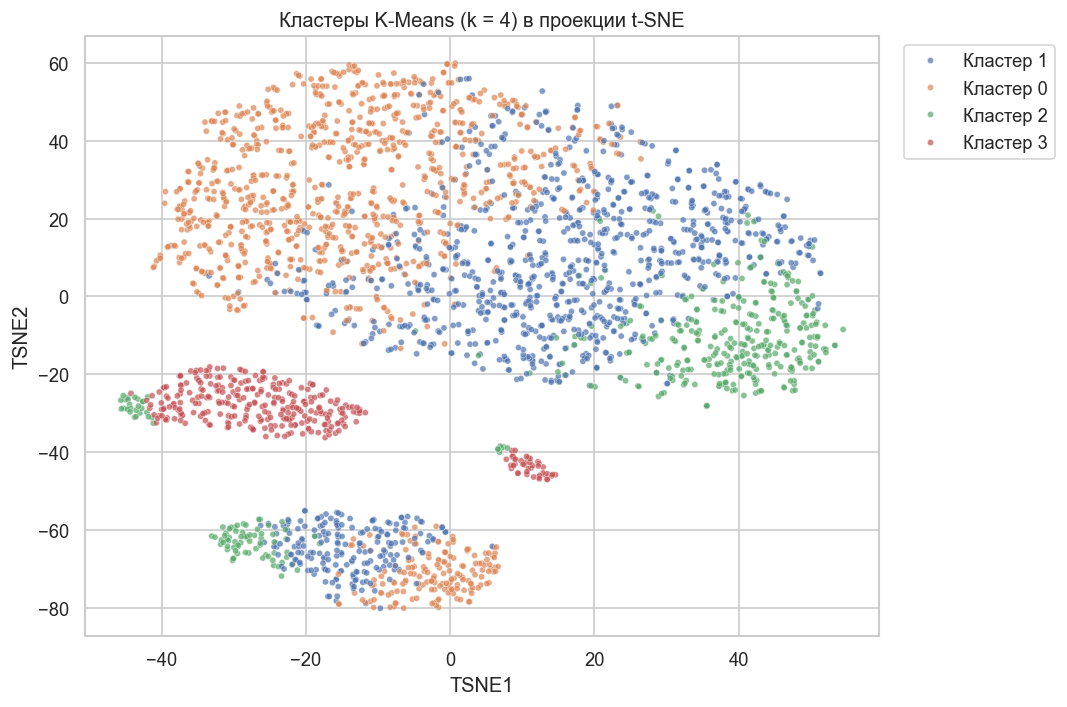

In [31]:
from sklearn.manifold import TSNE

tsne_idx = np.random.RandomState(RANDOM_STATE).choice(
    len(X_scaled), size=3000, replace=False
)
X_tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
).fit_transform(X_scaled[tsne_idx])
tsne_plot = pd.DataFrame(
    {
        "TSNE1": X_tsne[:, 0],
        "TSNE2": X_tsne[:, 1],
        "Кластер": np.char.add("Кластер ", labels_kmeans4[tsne_idx].astype(str)),
    }
)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=tsne_plot, x="TSNE1", y="TSNE2", hue="Кластер", s=14, alpha=0.7)
plt.title("Кластеры K-Means (k = 4) в проекции t-SNE")
plt.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("fig20_tsne.png")
plt.show()

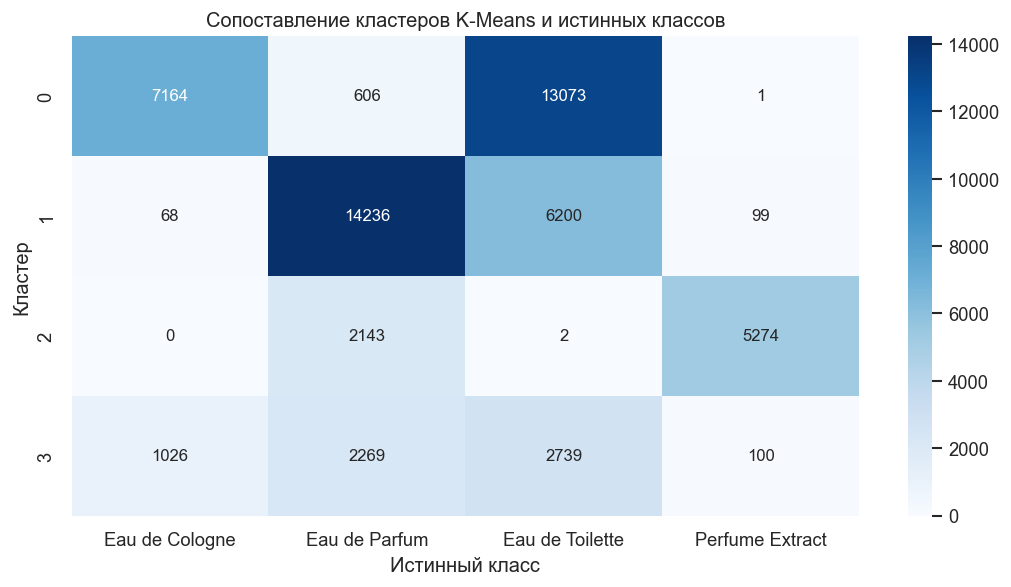

In [32]:
crosstab = pd.crosstab(labels_kmeans4, y)
plt.figure(figsize=(9, 5))
sns.heatmap(crosstab, annot=True, fmt="d", cmap="Blues")
plt.title("Сопоставление кластеров K-Means и истинных классов")
plt.xlabel("Истинный класс")
plt.ylabel("Кластер")
save_figure("fig19_crosstab.png")
plt.show()
RESULTS["crosstab"] = {
    "index": [int(value) for value in crosstab.index],
    "columns": [str(value) for value in crosstab.columns],
    "values": crosstab.to_numpy().astype(int).tolist(),
}

In [33]:
profile_df = df[num_cols].copy()
profile_df["cluster"] = labels_kmeans4
profiles = profile_df.groupby("cluster")[num_cols].mean()
profiles["size"] = pd.Series(labels_kmeans4).value_counts().sort_index()
profiles["dominant_class"] = crosstab.idxmax(axis=1)
RESULTS["profiles"] = {
    "means": {
        str(key): {column: float(value) for column, value in row.items()}
        for key, row in profiles[num_cols].to_dict(orient="index").items()
    },
    "sizes": {str(key): int(value) for key, value in profiles["size"].items()},
    "dominant_class": {
        str(key): str(value) for key, value in profiles["dominant_class"].items()
    },
}
profiles

,longevity_hours,sillage_score,top_note_count,price_usd,concentration_percent,contains_alcohol,limited_edition,size,dominant_class
cluster,,,,,,,,,
0,3.547649,3.820168,6.708933,56.664446,7.700860,0.855273,0.000000,20844,Eau de Toilette
1,6.467513,6.569002,4.629520,104.939767,15.548806,0.847096,0.000000,20603,Eau de Parfum
2,10.113990,8.025675,3.437660,210.456947,25.097465,0.859853,0.080873,7419,Perfume Extract
3,5.139257,5.302276,5.564069,84.910459,12.112763,0.855140,1.000000,6134,Eau de Toilette


In [34]:
def evaluate_subset(numeric_columns):
    subset_preprocessor = ColumnTransformer(
        transformers=[
            ("cat_tf", categorical_pipe, cat_cols),
            ("num_tf", numerical_pipe, numeric_columns),
        ]
    )
    X_subset = subset_preprocessor.fit_transform(df[numeric_columns + cat_cols])
    labels = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit_predict(
        X_subset
    )
    return {
        "silhouette": float(
            silhouette_score(
                X_subset,
                labels,
                sample_size=10000,
                random_state=RANDOM_STATE,
            )
        ),
        "ari": float(adjusted_rand_score(y, labels)),
        "nmi": float(normalized_mutual_info_score(y, labels)),
        "purity": float(purity_score(y, labels)),
    }


subset_rows = [
    {"features": "Все признаки", **evaluate_subset(num_cols)},
    {
        "features": "Без limited_edition",
        **evaluate_subset([column for column in num_cols if column != "limited_edition"]),
    },
    {
        "features": "Без бинарных флагов",
        **evaluate_subset(
            [
                column
                for column in num_cols
                if column not in ("limited_edition", "contains_alcohol")
            ]
        ),
    },
]
RESULTS["feature_subset"] = subset_rows
pd.DataFrame(subset_rows)

,features,silhouette,ari,nmi,purity
0,Все признаки,0.138206,0.321573,0.406583,0.642218
1,Без limited_edition,0.153006,0.312240,0.399766,0.639309
2,Без бинарных флагов,0.126444,0.247340,0.397888,0.590909


### b. Кросс-валидация устойчивости

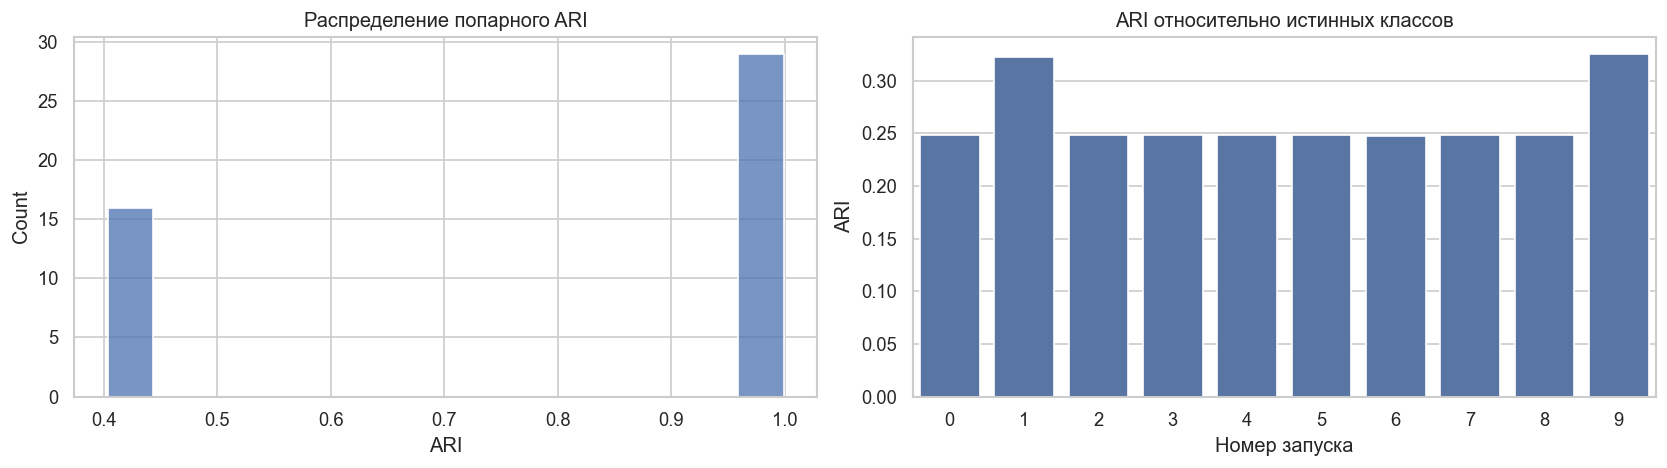

{'ari_vs_true_mean': 0.26331328139865023,
 'ari_vs_true_std': 0.030275276746001646,
 'pairwise_ari_mean': 0.7853564368008612,
 'pairwise_ari_std': 0.28029930903475286,
 'pairwise_ari_min': 0.4035145040461952,
 'pairwise_ari_max': 0.9991392503209041}

In [35]:
X_pool, X_eval, y_pool, y_eval = train_test_split(
    X_scaled, y, test_size=0.2, random_state=123, stratify=y
)

predictions = []
ari_true = []
for seed in range(10):
    X_sub, _, _, _ = train_test_split(
        X_pool, y_pool, train_size=0.8, random_state=seed, stratify=y_pool
    )
    model = KMeans(n_clusters=4, n_init=10, random_state=seed).fit(X_sub)
    prediction = model.predict(X_eval)
    predictions.append(prediction)
    ari_true.append(adjusted_rand_score(y_eval, prediction))

pairwise_ari = [
    adjusted_rand_score(predictions[i], predictions[j])
    for i in range(len(predictions))
    for j in range(i + 1, len(predictions))
]

stability = {
    "ari_vs_true_mean": float(np.mean(ari_true)),
    "ari_vs_true_std": float(np.std(ari_true)),
    "pairwise_ari_mean": float(np.mean(pairwise_ari)),
    "pairwise_ari_std": float(np.std(pairwise_ari)),
    "pairwise_ari_min": float(np.min(pairwise_ari)),
    "pairwise_ari_max": float(np.max(pairwise_ari)),
}
RESULTS["stability"] = stability

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(pairwise_ari, bins=15, ax=axes[0])
axes[0].set_title("Распределение попарного ARI")
axes[0].set_xlabel("ARI")
sns.barplot(x=range(len(ari_true)), y=ari_true, ax=axes[1])
axes[1].set_title("ARI относительно истинных классов")
axes[1].set_xlabel("Номер запуска")
axes[1].set_ylabel("ARI")
save_figure("fig20_stability.png")
plt.show()
stability


## Вывод

В ноутбуке последовательно выполнены первичный анализ, подготовка признаков,
обучение K-Means, DBSCAN и иерархической кластеризации, подбор гиперпараметров,
сравнение с реальными классами, экспертная интерпретация и кросс-валидация
устойчивости. Все рисунки сохранены в папке `artifacts` и используются при сборке отчёта.